# residual_v1

**Question.** Can v1 learn to use its own residual as a fault signal, instead of the fixed test-time rule of
`residual_flags`? A broken probe's reading should disagree with what the other probes imply; here the model is
trained to read that disagreement.

**Model** (`ResidualSHREDv1`, `configs/method/robust_shred_v1_residual.yaml`, `docs/protocol.md` row *Residual
v1*): one RobustSHRED v1 network (hidden 64, 4 heads, embed 32, null token, decoder 350/400) with 4 input channels
per probe (u, v, r_u, r_v), no mask input.
- **Pass 1:** residual channels at 0 → field prediction û₁.
- **Residual:** r = last-lag reading − û₁ at the probe's grid point (MinMax-scaled units, gradient stopped).
- **Pass 2:** the same network with r at every lag (faults are whole-window) → the output.
- **Loss:** MSE(pass 2) + 1.0 × MSE(pass 1), so pass 1 stays a good predictor.

**Training:** garbage, p = 0.3 per probe, **no flags** (as v1-garbage), noise on, Adam lr 1e-3, batch 64, up to
1000 epochs, early stopping on the pass-2 validation error. 3 seeds, MPS.

**Compared with** (cached runs, the same splits, masks, noise and garbage values): v1-garbage (same training, no
residual), v1-mixed (half its training faults flagged; the best model without an oracle so far, evaluated with no
flags), v1-missing with oracle flags (upper bound) and without flags. **Ablation:** the same trained network with
r = 0 (`pass1__*`). Conditions: garbage, exactly k of 8 probes faulty, 10 draws per test window; error = relative
L2 over the test snapshots (`err`).

**Check:** v1-garbage retrained with early stopping off (all 1000 epochs, final weights), same experiment and
draws, to test whether the gain over v1-garbage comes from training longer rather than from the residual.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

from get_shredded.runner import PROJECT_ROOT, load_results

OUT = PROJECT_ROOT / "outputs"
SEEDS = [0, 1, 2]
KS = list(range(8))
# label: (experiment, run, metric prefix)
ROWS = {
    "residual v1 (pass 2)": ("residual_v1", "robust_shred_v1_residual__garbage", "garbage_silent"),
    "residual v1, r = 0 (pass 1, ablation)": ("residual_v1", "robust_shred_v1_residual__garbage", "pass1__garbage_silent"),
    "v1-garbage, no flags": ("random_readings", "robust_shred_v1__garbage", "garbage_silent"),
    "v1-garbage, no flags, no early stopping (1000 epochs)": ("residual_v1", "robust_shred_v1__garbage__nostop",
                                                              "garbage_silent"),
    "v1-mixed, no flags": ("residual_flags_train", "robust_shred_v1__garbage_mixed", "garbage_silent"),
    "v1-missing, no flags": ("random_readings", "robust_shred_v1__missing", "garbage_silent"),
    "v1-missing, oracle flags": ("random_readings", "robust_shred_v1__missing", "garbage_oracle"),
}
RESULTS = {exp: load_results(OUT / exp / "nektar_uv") for exp in {e for e, _, _ in ROWS.values()}}

def errs(label, k):
    exp, run, prefix = ROWS[label]
    return [RESULTS[exp][(run, s)]["metrics"][f"{prefix}_k{k}"]["err"] for s in SEEDS]

def clean(label):
    exp, run, prefix = ROWS[label]
    key = "pass1__clean" if prefix.startswith("pass1") else "clean"
    return [RESULTS[exp][(run, s)]["metrics"][key]["err"] for s in SEEDS]

def ms(v, d=4):
    return f"{np.mean(v):.{d}f} ± {np.std(v):.{d}f}"

def table(header, rows):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(r) + " |" for r in rows]
    return Markdown("\n".join(lines))

devices = {RESULTS[e][(r, s)]["device"] for e, r, _ in ROWS.values() for s in SEEDS}
display(Markdown(f"Devices of all compared runs: {devices}"))

Devices of all compared runs: {'mps'}

## 1. Field error (mean ± std over 3 seeds)

| method | clean | k=0 | k=1 | k=2 | k=3 | k=4 | k=7 |
|---|---|---|---|---|---|---|---|
| residual v1 (pass 2) | 0.0246 ± 0.0045 | 0.0248 ± 0.0046 | 0.0325 ± 0.0032 | 0.0413 ± 0.0029 | 0.0554 ± 0.0051 | 0.0810 ± 0.0118 | 0.2840 ± 0.0110 |
| residual v1, r = 0 (pass 1, ablation) | 0.0259 ± 0.0046 | 0.0261 ± 0.0047 | 0.0336 ± 0.0031 | 0.0424 ± 0.0033 | 0.0560 ± 0.0060 | 0.0793 ± 0.0103 | 0.2847 ± 0.0086 |
| v1-garbage, no flags | 0.0318 ± 0.0026 | 0.0319 ± 0.0025 | 0.0405 ± 0.0038 | 0.0551 ± 0.0072 | 0.0747 ± 0.0074 | 0.1110 ± 0.0131 | 0.3044 ± 0.0079 |
| v1-garbage, no flags, no early stopping (1000 epochs) | 0.0269 ± 0.0045 | 0.0271 ± 0.0044 | 0.0293 ± 0.0046 | 0.0341 ± 0.0048 | 0.0411 ± 0.0049 | 0.0667 ± 0.0127 | 0.3082 ± 0.0031 |
| v1-mixed, no flags | 0.0169 ± 0.0049 | 0.0170 ± 0.0047 | 0.0220 ± 0.0025 | 0.0301 ± 0.0023 | 0.0387 ± 0.0036 | 0.0678 ± 0.0078 | 0.2925 ± 0.0053 |
| v1-missing, no flags | 0.0101 ± 0.0008 | 0.0110 ± 0.0008 | 0.0715 ± 0.0129 | 0.1231 ± 0.0268 | 0.1687 ± 0.0263 | 0.2153 ± 0.0259 | 0.3415 ± 0.0306 |
| v1-missing, oracle flags | 0.0101 ± 0.0008 | 0.0110 ± 0.0008 | 0.0115 ± 0.0009 | 0.0125 ± 0.0011 | 0.0146 ± 0.0011 | 0.0187 ± 0.0025 | 0.1258 ± 0.0145 |

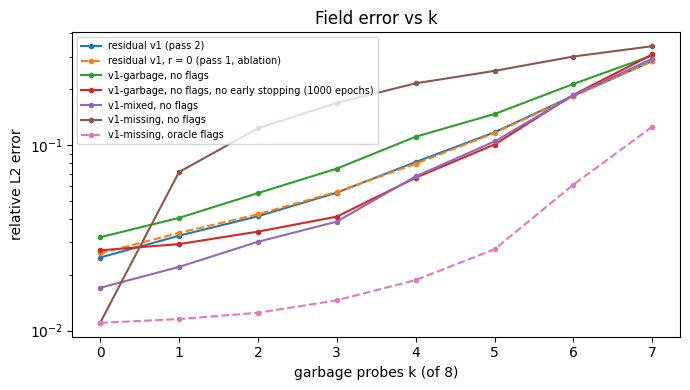

In [2]:
SHOW = [0, 1, 2, 3, 4, 7]
display(table(["method", "clean"] + [f"k={k}" for k in SHOW],
              [[lab, ms(clean(lab))] + [ms(errs(lab, k)) for k in SHOW] for lab in ROWS]))

fig, ax = plt.subplots(figsize=(7, 4))
for lab in ROWS:
    m = np.array([np.mean(errs(lab, k)) for k in KS])
    ax.plot(KS, m, marker="o", ms=3, ls="--" if "r = 0" in lab or "oracle" in lab else "-", label=lab)
ax.set(xlabel="garbage probes k (of 8)", ylabel="relative L2 error", yscale="log", title="Field error vs k")
ax.legend(fontsize=7)
fig.tight_layout()

## 2. Per seed at k = 1, 2, 4

Whether a difference holds on every seed.

In [3]:
for k in (1, 2, 4):
    display(Markdown(f"**k = {k}**"))
    display(table(["method"] + [f"seed {s}" for s in SEEDS],
                  [[lab] + [f"{e:.4f}" for e in errs(lab, k)] for lab in ROWS]))

**k = 1**

| method | seed 0 | seed 1 | seed 2 |
|---|---|---|---|
| residual v1 (pass 2) | 0.0311 | 0.0294 | 0.0369 |
| residual v1, r = 0 (pass 1, ablation) | 0.0319 | 0.0310 | 0.0380 |
| v1-garbage, no flags | 0.0365 | 0.0393 | 0.0457 |
| v1-garbage, no flags, no early stopping (1000 epochs) | 0.0315 | 0.0334 | 0.0229 |
| v1-mixed, no flags | 0.0204 | 0.0255 | 0.0201 |
| v1-missing, no flags | 0.0716 | 0.0557 | 0.0872 |
| v1-missing, oracle flags | 0.0123 | 0.0103 | 0.0120 |

**k = 2**

| method | seed 0 | seed 1 | seed 2 |
|---|---|---|---|
| residual v1 (pass 2) | 0.0379 | 0.0451 | 0.0411 |
| residual v1, r = 0 (pass 1, ablation) | 0.0385 | 0.0465 | 0.0422 |
| v1-garbage, no flags | 0.0454 | 0.0573 | 0.0625 |
| v1-garbage, no flags, no early stopping (1000 epochs) | 0.0368 | 0.0382 | 0.0275 |
| v1-mixed, no flags | 0.0284 | 0.0334 | 0.0285 |
| v1-missing, no flags | 0.1258 | 0.0891 | 0.1545 |
| v1-missing, oracle flags | 0.0132 | 0.0110 | 0.0132 |

**k = 4**

| method | seed 0 | seed 1 | seed 2 |
|---|---|---|---|
| residual v1 (pass 2) | 0.0681 | 0.0966 | 0.0784 |
| residual v1, r = 0 (pass 1, ablation) | 0.0681 | 0.0930 | 0.0767 |
| v1-garbage, no flags | 0.1004 | 0.1295 | 0.1031 |
| v1-garbage, no flags, no early stopping (1000 epochs) | 0.0670 | 0.0821 | 0.0510 |
| v1-mixed, no flags | 0.0575 | 0.0765 | 0.0695 |
| v1-missing, no flags | 0.2201 | 0.1816 | 0.2444 |
| v1-missing, oracle flags | 0.0213 | 0.0153 | 0.0197 |

## 3. Training

In [4]:
rows = []
for lab, (exp, run, prefix) in ROWS.items():
    if prefix.startswith("pass1") or "oracle" in lab:
        continue
    r = [RESULTS[exp][(run, s)] for s in SEEDS]
    rows.append([lab, ms([x["metrics"]["epochs_used"] * 20 for x in r], 0), ms([x["wall_time_s"] for x in r], 0),
                 ms([x["metrics"]["train"]["err"] for x in r]) if "train" in r[0]["metrics"] else "– (not recorded)",
                 f"{r[0]['metrics']['parameters']:,}"])
display(table(["model", "epochs (≈ validation checks × 20)", "wall time (s)", "train error (clean)", "parameters"], rows))

| model | epochs (≈ validation checks × 20) | wall time (s) | train error (clean) | parameters |
|---|---|---|---|---|
| residual v1 (pass 2) | 513 ± 47 | 157 ± 18 | 0.0243 ± 0.0045 | 4,224,446 |
| v1-garbage, no flags | 353 ± 47 | 50 ± 15 | – (not recorded) | 4,224,382 |
| v1-garbage, no flags, no early stopping (1000 epochs) | 1020 ± 0 | 189 ± 4 | 0.0229 ± 0.0037 | 4,224,382 |
| v1-mixed, no flags | 700 ± 220 | 135 ± 43 | 0.0166 ± 0.0043 | 4,224,382 |
| v1-missing, no flags | 540 ± 43 | 84 ± 6 | – (not recorded) | 4,224,382 |

## 4. Notes

Conclusion (agreed with the user, tentative): `experiments/residual_v1/README.md`. The residual adds no measurable gain; the apparent gain over v1-garbage was longer training, as v1-garbage without early stopping shows. The epochs column counts validation checks × 20, so 1000 epochs show as 1020.